In [1]:
import numpy as np
import pandas as pd
import joblib
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Set to False if f is itself yz/(z^2+1) (avoids copying the 4th column)
USE_G = True

In [2]:
df = pd.read_csv("data.csv")          # columns: x, y, z, f
df["g"] = df["y"] * df["z"] / (df["z"] ** 2 + 1)

features = ["x", "y", "z", "g"] if USE_G else ["x", "y", "z"]
X = df[features].values.astype("float32")
y = df["f"].values.astype("float32")

print(df.shape)
df.head()

(30000, 6)


,sr_no,x,y,z,f,g
0,0,-81.676226,-62.424837,48.488491,-0.389217,-1.286868
1,1,48.848608,-22.458462,-17.243589,2.618250,1.298058
2,2,-4.091858,35.213060,-70.472387,-0.868348,-0.499571
3,3,86.376067,-72.306590,-42.694652,3.207185,1.692646
4,4,-71.361489,-36.541999,-54.975949,0.389713,0.664471


In [3]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.10, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.90, random_state=SEED)

print(f"train={len(X_train)}  val={len(X_val)}  test={len(X_test)}")

train=22500  val=4500  test=3000


In [4]:
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train.reshape(-1, 1))

X_train_s = x_scaler.transform(X_train)
X_val_s   = x_scaler.transform(X_val)
X_test_s  = x_scaler.transform(X_test)

y_train_s = y_scaler.transform(y_train.reshape(-1, 1)).ravel()
y_val_s   = y_scaler.transform(y_val.reshape(-1, 1)).ravel()

joblib.dump(x_scaler, "x_scaler.pkl")
joblib.dump(y_scaler, "y_scaler.pkl")

['y_scaler.pkl']

In [5]:
model = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(256, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(64,  activation="relu"),
    layers.Dense(1),                      # linear output
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="mse", metrics=["mae"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                     ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                    │ (None, 256)              │         1,280 │
├──────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                  │ (None, 256)              │        65,792 │
├──────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_2 (Dense)                  │ (None, 128)              │        32,896 │
├──────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_3 (Dense)                  │ (None, 64)               │         8,256 │
├──────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_4 (Dense)                  │ (None, 1)                │            65 │
└──────────────────────────────────┴──────────────────────────┴───────────────┘

 Total params: 108,289 (423.00 KB)

 Trainable params: 108,289 (423.00 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
lr_decay = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.33, patience=10, min_lr=1e-7, verbose=1)

early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=40, restore_best_weights=True, verbose=1)

checkpoint = callbacks.ModelCheckpoint(
    "best_model.keras", monitor="val_loss", save_best_only=True)

In [7]:
history = model.fit(
    X_train_s, y_train_s,
    validation_data=(X_val_s, y_val_s),
    epochs=200, batch_size=128,
    callbacks=[lr_decay, early_stop, checkpoint],
    verbose=2)

Epoch 1/200
176/176 - 5s - 31ms/step - loss: 0.0511 - mae: 0.1118 - val_loss: 0.0126 - val_mae: 0.0911 - learning_rate: 0.0010
Epoch 2/200
176/176 - 6s - 34ms/step - loss: 0.0127 - mae: 0.0913 - val_loss: 0.0135 - val_mae: 0.0940 - learning_rate: 0.0010
Epoch 3/200
176/176 - 1s - 7ms/step - loss: 0.0123 - mae: 0.0900 - val_loss: 0.0135 - val_mae: 0.0942 - learning_rate: 0.0010
Epoch 4/200
176/176 - 1s - 7ms/step - loss: 0.0123 - mae: 0.0899 - val_loss: 0.0133 - val_mae: 0.0937 - learning_rate: 0.0010
Epoch 5/200
176/176 - 1s - 6ms/step - loss: 0.0124 - mae: 0.0901 - val_loss: 0.0129 - val_mae: 0.0923 - learning_rate: 0.0010
Epoch 6/200
176/176 - 1s - 7ms/step - loss: 0.0124 - mae: 0.0900 - val_loss: 0.0119 - val_mae: 0.0889 - learning_rate: 0.0010
Epoch 7/200
176/176 - 1s - 8ms/step - loss: 0.0128 - mae: 0.0909 - val_loss: 0.0117 - val_mae: 0.0883 - learning_rate: 0.0010
Epoch 8/200
176/176 - 1s - 7ms/step - loss: 0.0124 - mae: 0.0901 - val_loss: 0.0121 - val_mae: 0.0898 - learning_rat

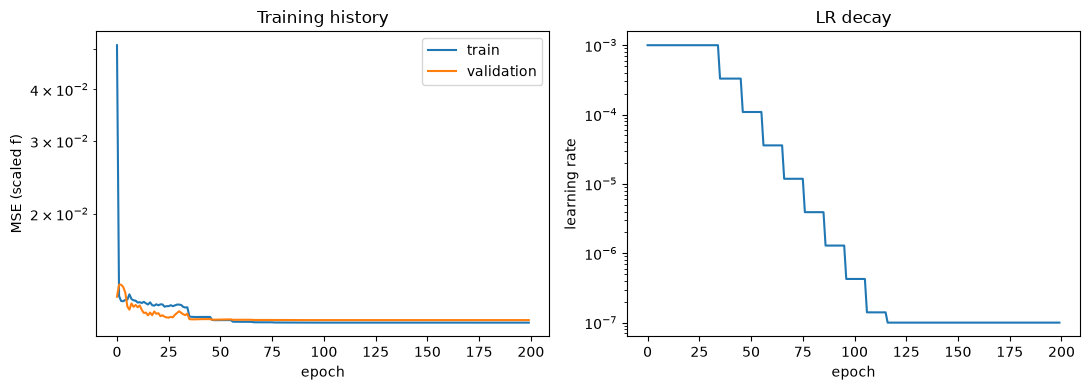

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_yscale("log")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE (scaled f)")
ax[0].set_title("Training history"); ax[0].legend()

if "learning_rate" in history.history:
    ax[1].plot(history.history["learning_rate"])
    ax[1].set_yscale("log")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("learning rate")
    ax[1].set_title("LR decay")

plt.tight_layout()
plt.savefig("training_history.png", dpi=150)
plt.show()

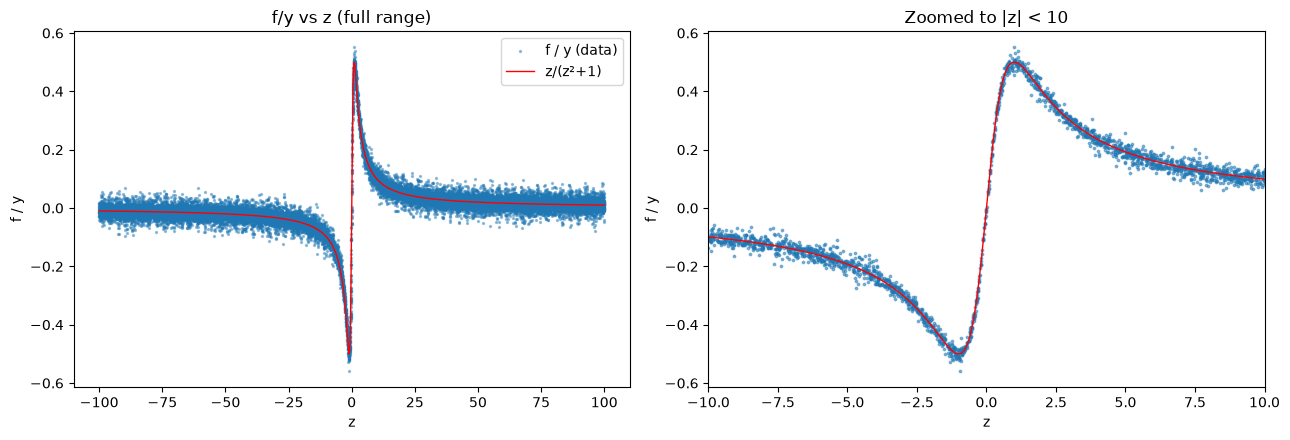

residual std: 0.5319462176265747 | f std: 5.0763267840401785
max |residual|: 1.9754145986651146


In [9]:
m = np.abs(df["y"]) > 20            # skip tiny y, where f/y blows up
z_m = df.loc[m, "z"]
ratio = df.loc[m, "f"] / df.loc[m, "y"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# full range
ax[0].scatter(z_m, ratio, s=2, alpha=0.4, label="f / y (data)")
zz = np.linspace(-100, 100, 4000)
ax[0].plot(zz, zz / (zz**2 + 1), "r", lw=1, label="z/(z²+1)")
ax[0].set_xlabel("z"); ax[0].set_ylabel("f / y")
ax[0].set_title("f/y vs z (full range)"); ax[0].legend()

# zoomed near z = 0
ax[1].scatter(z_m, ratio, s=3, alpha=0.5)
zz = np.linspace(-10, 10, 2000)
ax[1].plot(zz, zz / (zz**2 + 1), "r", lw=1)
ax[1].set_xlim(-10, 10)
ax[1].set_xlabel("z"); ax[1].set_ylabel("f / y")
ax[1].set_title("Zoomed to |z| < 10")

plt.tight_layout(); plt.show()

# how close is f to y*z/(z²+1)?
resid = df["f"] - df["y"] * df["z"] / (df["z"]**2 + 1)
print("residual std:", resid.std(), "| f std:", df["f"].std())
print("max |residual|:", resid.abs().max())

In [10]:
best = keras.models.load_model("best_model.keras")
y_pred = y_scaler.inverse_transform(best.predict(X_test_s)).ravel()

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae  = mean_absolute_error(y_test, y_pred)
r2   = r2_score(y_test, y_pred)
print(f"TEST  RMSE={rmse:.5f}  MAE={mae:.5f}  R2={r2:.5f}")

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
TEST  RMSE=0.53245  MAE=0.43564  R2=0.98912


In [11]:
from sklearn.linear_model import LinearRegression
g = (df["y"] * df["z"] / (df["z"]**2 + 1)).values.reshape(-1, 1)
lr = LinearRegression().fit(g, df["f"])
print("R² of f vs g:", lr.score(g, df["f"]), "| slope:", lr.coef_[0])

R² of f vs g: 0.9890203615752069 | slope: 0.9988904112271805


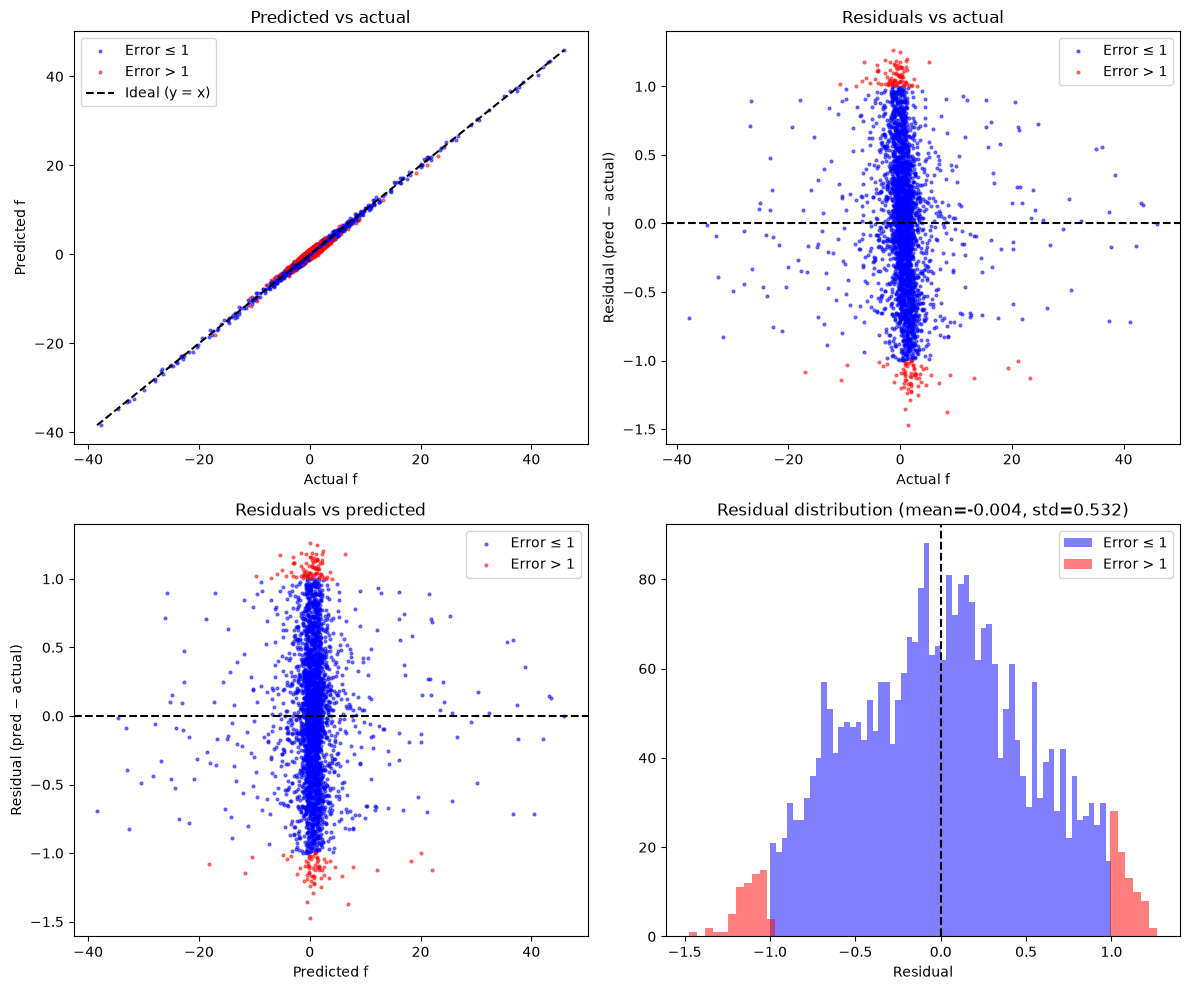

In [12]:
resid = y_pred - y_test

# Separate points based on absolute error
small_error = np.abs(resid) <= 1
large_error = np.abs(resid) > 1

fig, ax = plt.subplots(2, 2, figsize=(12, 10))

# 1. Predicted vs actual
lims = [min(y_test.min(), y_pred.min()),
        max(y_test.max(), y_pred.max())]

ax[0, 0].scatter(y_test[small_error], y_pred[small_error],
                 s=4, alpha=0.5, color="blue", label="Error ≤ 1")

ax[0, 0].scatter(y_test[large_error], y_pred[large_error],
                 s=4, alpha=0.5, color="red", label="Error > 1")

ax[0, 0].plot(lims, lims, "k--", label="Ideal (y = x)")
ax[0, 0].set_xlabel("Actual f")
ax[0, 0].set_ylabel("Predicted f")
ax[0, 0].set_title("Predicted vs actual")
ax[0, 0].legend()


# 2. Residuals vs actual
ax[0, 1].scatter(y_test[small_error], resid[small_error],
                 s=4, alpha=0.5, color="blue", label="Error ≤ 1")

ax[0, 1].scatter(y_test[large_error], resid[large_error],
                 s=4, alpha=0.5, color="red", label="Error > 1")

ax[0, 1].axhline(0, color="black", ls="--")
ax[0, 1].set_xlabel("Actual f")
ax[0, 1].set_ylabel("Residual (pred − actual)")
ax[0, 1].set_title("Residuals vs actual")
ax[0, 1].legend()


# 3. Residuals vs predicted
ax[1, 0].scatter(y_pred[small_error], resid[small_error],
                 s=4, alpha=0.5, color="blue", label="Error ≤ 1")

ax[1, 0].scatter(y_pred[large_error], resid[large_error],
                 s=4, alpha=0.5, color="red", label="Error > 1")

ax[1, 0].axhline(0, color="black", ls="--")
ax[1, 0].set_xlabel("Predicted f")
ax[1, 0].set_ylabel("Residual (pred − actual)")
ax[1, 0].set_title("Residuals vs predicted")
ax[1, 0].legend()


# 4. Residual histogram
ax[1, 1].hist(resid[small_error], bins=60,
              color="blue", alpha=0.5, label="Error ≤ 1")

ax[1, 1].hist(resid[large_error], bins=60,
              color="red", alpha=0.5, label="Error > 1")

ax[1, 1].axvline(0, color="black", ls="--")
ax[1, 1].set_xlabel("Residual")
ax[1, 1].set_title(
    f"Residual distribution (mean={resid.mean():.3f}, std={resid.std():.3f})"
)
ax[1, 1].legend()

plt.tight_layout()
plt.savefig("residual_analysis.png", dpi=150)
plt.show()

std: 0.5319373517823983 | min/max: -0.8754987330409136 1.9754145986651146


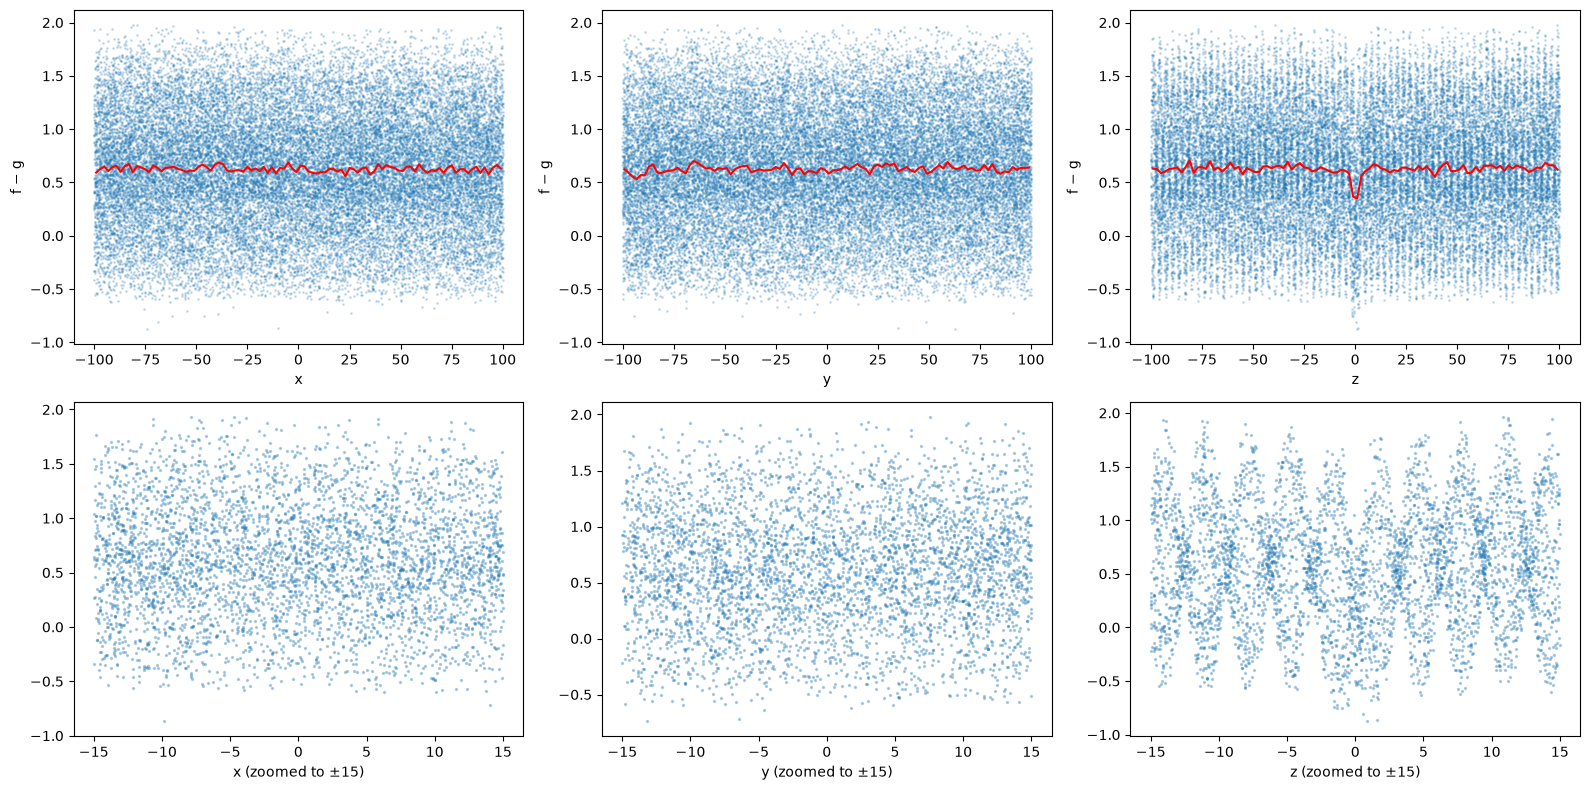

In [13]:
g = df["y"] * df["z"] / (df["z"]**2 + 1)
r = (df["f"] - g).values
print("std:", r.std(), "| min/max:", r.min(), r.max())

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for j, col in enumerate(["x", "y", "z"]):
    v = df[col].values
    ax[0, j].scatter(v, r, s=1, alpha=0.2)
    bins = np.linspace(v.min(), v.max(), 101)
    idx = np.digitize(v, bins)
    means = [r[idx == i].mean() for i in range(1, 101)]
    ax[0, j].plot(0.5 * (bins[1:] + bins[:-1]), means, "r", lw=1.5)
    ax[0, j].set_xlabel(col); ax[0, j].set_ylabel("f − g")
    # zoomed view to catch fast oscillations
    m = np.abs(v) < 15
    ax[1, j].scatter(v[m], r[m], s=2, alpha=0.3)
    ax[1, j].set_xlabel(f"{col} (zoomed to ±15)")
plt.tight_layout(); plt.show()

In [14]:
from sklearn.ensemble import HistGradientBoostingRegressor
Xr = df[["x", "y", "z"]].values
Xa, Xb, ra, rb = train_test_split(Xr, r, test_size=0.2, random_state=42)
gb = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05).fit(Xa, ra)
print("held-out R² on the leftover:", gb.score(Xb, rb))

held-out R² on the leftover: 0.0037427053621968964


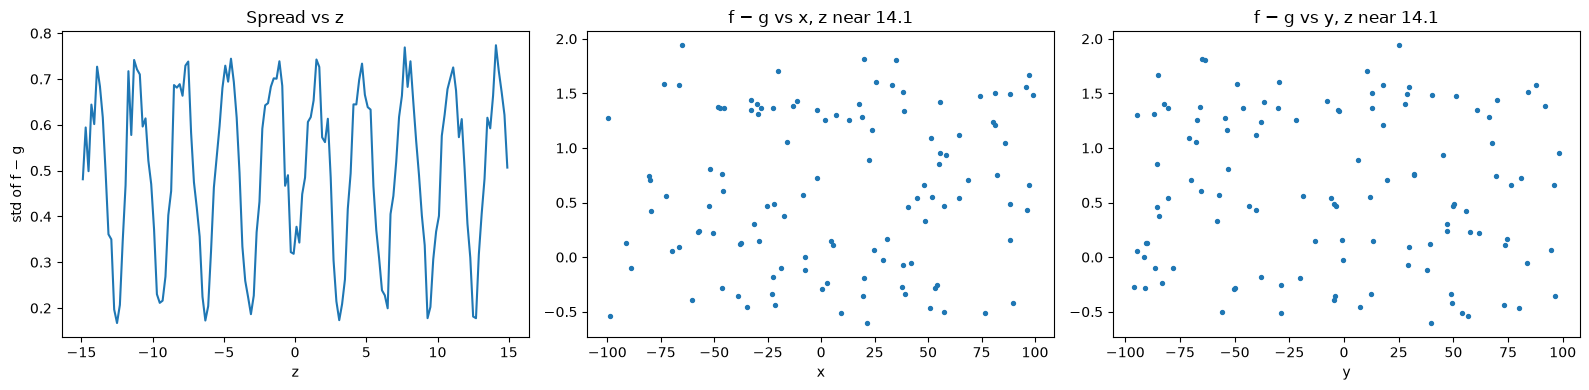

In [15]:
r = (df["f"] - df["y"] * df["z"] / (df["z"]**2 + 1)).values
zv = df["z"].values

# (a) how the spread of the leftover varies with z
m = np.abs(zv) < 15
bins = np.arange(-15, 15.01, 0.2)
idx = np.digitize(zv[m], bins)
centers = 0.5 * (bins[1:] + bins[:-1])
sd = np.array([r[m][idx == i].std() if (idx == i).sum() > 5 else np.nan
               for i in range(1, len(bins))])

# (b) in the widest-spread stripe, does the leftover follow x or y?
z0 = centers[np.nanargmax(sd)]
s = np.abs(zv - z0) < 0.4

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(centers, sd); ax[0].set_xlabel("z"); ax[0].set_ylabel("std of f − g")
ax[0].set_title("Spread vs z")
ax[1].scatter(df["x"][s], r[s], s=8); ax[1].set_xlabel("x")
ax[1].set_title(f"f − g vs x, z near {z0:.1f}")
ax[2].scatter(df["y"][s], r[s], s=8); ax[2].set_xlabel("y")
ax[2].set_title(f"f − g vs y, z near {z0:.1f}")
plt.tight_layout(); plt.show()


In [16]:
   v = (r - r.mean())**2
   Xa, Xb, va, vb = train_test_split(df[["x","y","z"]].values, v, test_size=0.2, random_state=42)
   gb2 = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05).fit(Xa, va)
   print("R² on squared leftover:", gb2.score(Xb, vb))

R² on squared leftover: 0.15429121549315872


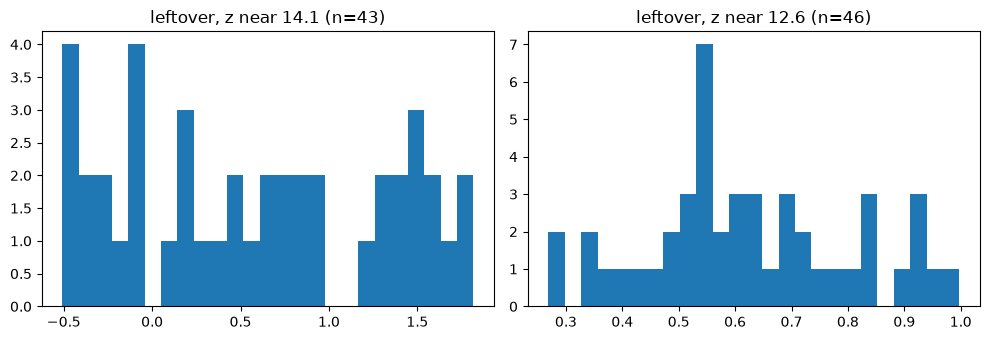

In [17]:
r = (df["f"] - df["y"] * df["z"] / (df["z"]**2 + 1)).values
zv = df["z"].values
# pick a peak and a trough of the spread curve, e.g. near z=14.1 and its trough
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, z0 in zip(ax, [14.1, 12.6]):      # change 12.6 to a trough you read off the plot
    s = np.abs(zv - z0) < 0.15
    a.hist(r[s], bins=25); a.set_title(f"leftover, z near {z0} (n={s.sum()})")
plt.tight_layout(); plt.show()

In [18]:
w = 2.0
df["g"] = df["y"] * df["z"] / (df["z"]**2 + 1)
df["sz"], df["cz"] = np.sin(w * df["z"]), np.cos(w * df["z"])
feats = ["x", "y", "z", "sz", "cz"]
target = (df["f"] - df["g"]).values.astype("float32")

Xa, Xtmp, ya, ytmp = train_test_split(df[feats].values, target, test_size=0.25, random_state=SEED)
Xv, Xt, yv, yt = train_test_split(Xtmp, ytmp, test_size=0.4, random_state=SEED)   # 15% / 10% of total
sc = StandardScaler().fit(Xa)
Xa_s, Xv_s, Xt_s = sc.transform(Xa), sc.transform(Xv), sc.transform(Xt)

def gaussian_nll(y_true, y_pred):
    y_true = tf.reshape(y_true, (-1, 1))
    mu, log_var = y_pred[:, 0:1], y_pred[:, 1:2]
    return tf.reduce_mean(0.5 * (log_var + tf.square(y_true - mu) * tf.exp(-log_var)))

net = keras.Sequential([
    layers.Input(shape=(len(feats),)),
    layers.Dense(64, activation="tanh"),
    layers.Dense(64, activation="tanh"),
    layers.Dense(32, activation="tanh"),
    layers.Dense(2),                      # [mean of leftover, log-variance]
])
net.compile(optimizer=keras.optimizers.Adam(1e-3), loss=gaussian_nll)

net.fit(Xa_s, ya, validation_data=(Xv_s, yv), epochs=300, batch_size=128, verbose=2,
        callbacks=[callbacks.ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-6),
                   callbacks.EarlyStopping(patience=30, min_delta=1e-4, restore_best_weights=True)])

Epoch 1/300
176/176 - 3s - 19ms/step - loss: -0.1608 - val_loss: -0.2451 - learning_rate: 0.0010
Epoch 2/300
176/176 - 1s - 5ms/step - loss: -0.2469 - val_loss: -0.2591 - learning_rate: 0.0010
Epoch 3/300
176/176 - 1s - 5ms/step - loss: -0.2549 - val_loss: -0.2654 - learning_rate: 0.0010
Epoch 4/300
176/176 - 1s - 5ms/step - loss: -0.2580 - val_loss: -0.2675 - learning_rate: 0.0010
Epoch 5/300
176/176 - 1s - 8ms/step - loss: -0.2596 - val_loss: -0.2681 - learning_rate: 0.0010
Epoch 6/300
176/176 - 1s - 5ms/step - loss: -0.2610 - val_loss: -0.2684 - learning_rate: 0.0010
Epoch 7/300
176/176 - 1s - 8ms/step - loss: -0.2622 - val_loss: -0.2687 - learning_rate: 0.0010
Epoch 8/300
176/176 - 1s - 5ms/step - loss: -0.2631 - val_loss: -0.2694 - learning_rate: 0.0010
Epoch 9/300
176/176 - 1s - 8ms/step - loss: -0.2638 - val_loss: -0.2704 - learning_rate: 0.0010
Epoch 10/300
176/176 - 1s - 4ms/step - loss: -0.2644 - val_loss: -0.2717 - learning_rate: 0.0010
Epoch 11/300
176/176 - 1s - 5ms/step -

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
RMSE of mean: 0.54024875
coverage of ±2σ: 0.9913333333333333


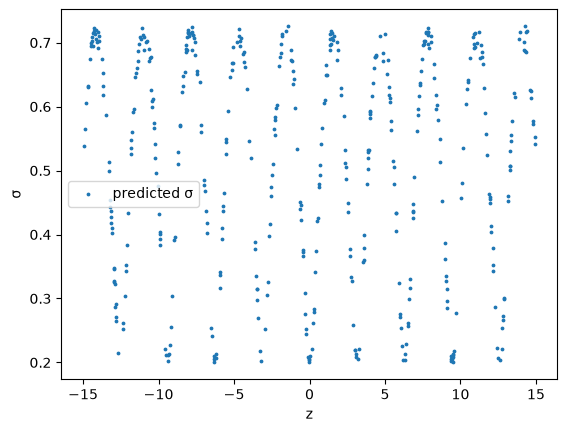

In [19]:
out = net.predict(Xt_s)
mu, sigma = out[:, 0], np.exp(0.5 * out[:, 1])
print("RMSE of mean:", np.sqrt(np.mean((mu - yt)**2)))   # expect ~0.53 again
print("coverage of ±2σ:", np.mean(np.abs(yt - mu) < 2 * sigma))   # expect ~0.95 if calibrated

ztest = Xt[:, 2]; m = np.abs(ztest) < 15
plt.scatter(ztest[m], sigma[m], s=3, label="predicted σ")
plt.xlabel("z"); plt.ylabel("σ"); plt.legend(); plt.show()   # should show the same wave as your plot

In [20]:
za, rz = Xa[:, 2], ya
m = np.abs(za) < 30
bw = 0.25
edges = np.arange(-30, 30 + bw, bw)
idx = np.digitize(za[m], edges) - 1
sd = np.array([rz[m][idx == i].std() if (idx == i).sum() > 5 else np.nan
               for i in range(len(edges) - 1)])
sd = np.where(np.isnan(sd), np.nanmean(sd), sd)
sd = sd - sd.mean()

freqs = np.fft.rfftfreq(len(sd), d=bw)          # cycles per unit of z
power = np.abs(np.fft.rfft(sd))**2
k = np.argmax(power[1:]) + 1
print("spread period ≈", 1 / freqs[k], "| w = 2π/period =", 2 * np.pi * freqs[k])


spread period ≈ 3.1578947368421053 | w = 2π/period = 1.9896753472735356


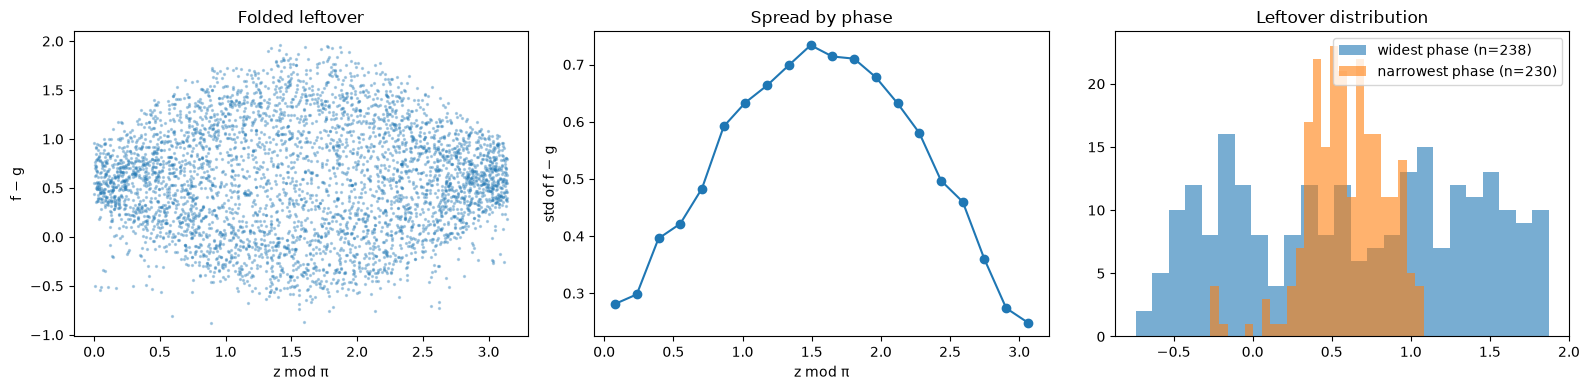

In [21]:
r = (df["f"] - df["y"] * df["z"] / (df["z"]**2 + 1)).values
z = df["z"].values
m = np.abs(z) < 15                      # keeps phase drift from a slightly wrong period small
phase = np.mod(z[m], np.pi)
rm = r[m]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(phase, rm, s=2, alpha=0.3)
ax[0].set_xlabel("z mod π"); ax[0].set_ylabel("f − g"); ax[0].set_title("Folded leftover")

edges = np.linspace(0, np.pi, 21)
idx = np.digitize(phase, edges) - 1
sd = np.array([rm[idx == i].std() for i in range(20)])
ax[1].plot(0.5 * (edges[1:] + edges[:-1]), sd, "o-")
ax[1].set_xlabel("z mod π"); ax[1].set_ylabel("std of f − g"); ax[1].set_title("Spread by phase")

hi, lo = np.argmax(sd), np.argmin(sd)
ax[2].hist(rm[idx == hi], bins=25, alpha=0.6, label=f"widest phase (n={np.sum(idx==hi)})")
ax[2].hist(rm[idx == lo], bins=25, alpha=0.6, label=f"narrowest phase (n={np.sum(idx==lo)})")
ax[2].set_title("Leftover distribution"); ax[2].legend()
plt.tight_layout(); plt.show()


In [22]:
   r = (df["f"] - df["y"] * df["z"] / (df["z"]**2 + 1)).values
   z = df["z"].values
   c = np.median(r)
   s2 = np.sin(z)**2
   A = np.column_stack([np.ones_like(s2), s2])
   coef, *_ = np.linalg.lstsq(A, (r - c)**2, rcond=None)
   pred = A @ coef
   r2 = 1 - np.sum(((r - c)**2 - pred)**2) / np.sum(((r - c)**2 - ((r - c)**2).mean())**2)
   print("a, b =", coef, "| R² of variance fit:", r2)

a, b = [0.03894615 0.48860244] | R² of variance fit: 0.2643716413508539


rows: 4693


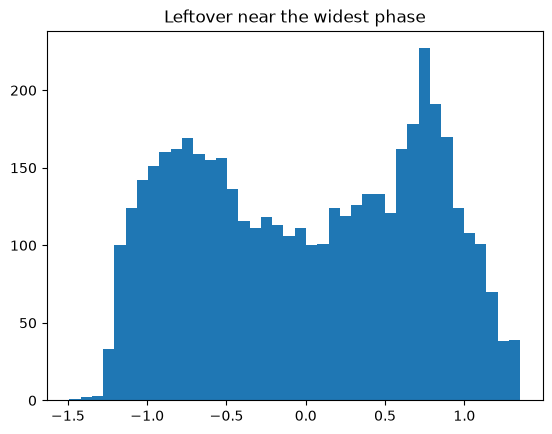

|z|>60, phase 0.00-0.30: std = 0.211 (n=1072)
|z|>60, phase 1.42-1.72: std = 0.738 (n=1198)


In [23]:
   phase = np.mod(z, np.pi)
   sel = np.abs(phase - np.pi / 2) < 0.25
   print("rows:", sel.sum())
   plt.hist(r[sel] - c, bins=40); plt.title("Leftover near the widest phase"); plt.show()

   # period check using far-away rows only
   far = np.abs(z) > 60
   for lo, hi in [(0, 0.3), (np.pi/2 - 0.15, np.pi/2 + 0.15)]:
       m = far & (phase >= lo) & (phase < hi)
       print(f"|z|>60, phase {lo:.2f}-{hi:.2f}: std = {r[m].std():.3f} (n={m.sum()})")

In [24]:
import os, time, traceback, warnings
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from scipy.signal import lombscargle
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

OUT = "lunch_run"; os.makedirs(OUT, exist_ok=True)
LOG = open(f"{OUT}/results.txt", "w", encoding="utf-8")
def log(*a):
    s = " ".join(str(v) for v in a)
    print(s, flush=True)
    LOG.write(s + "\n"); LOG.flush()

# ---------- data and split (same as the mean+spread run) ----------
SEED = 42
df = pd.read_csv("data.csv")
x, y, z = df["x"].values, df["y"].values, df["z"].values
f = df["f"].values
g = y * z / (z**2 + 1)
r = (f - g).astype("float32")                      # the leftover = our target
idx = np.arange(len(df))
i_tr, i_tmp = train_test_split(idx, test_size=0.25, random_state=SEED)
i_va, i_te = train_test_split(i_tmp, test_size=0.4, random_state=SEED)
log(f"train={len(i_tr)} val={len(i_va)} test={len(i_te)}")

# ---------- 1. periodogram search (TRAIN rows only) ----------
sz = np.sin(z)
sel = i_tr[np.abs(sz[i_tr]) > 0.97]                # rows where the sin(z) term is at full strength
u = (r[sel] - np.median(r[i_tr])) * np.sign(sz[sel])   # undo the sign flip
log(f"periodogram rows: {len(sel)}")

found = {}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
w = np.linspace(0.02, 40, 6000)                    # angular frequency, radians per unit
for a, (name, v) in zip(ax, [("x", x), ("y", y)]):
    vv, uc = v[sel].astype("float64"), (u - u.mean()).astype("float64")
    p = lombscargle(vv, uc, w, normalize=True)
    rng = np.random.default_rng(0)
    null = max(lombscargle(vv, rng.permutation(uc), w, normalize=True).max() for _ in range(20))
    k = p.argmax()
    ratio = p[k] / null
    log(f"{name}: peak w={w[k]:.3f} (period {2*np.pi/w[k]:.3f}), power {p[k]:.4f}, "
        f"best of 20 shuffles {null:.4f}, ratio {ratio:.2f}")
    if ratio > 1.3:
        found[name] = float(w[k])
    a.plot(w, p); a.axhline(null, color="r", ls="--", label="best shuffle")
    a.set_xlabel(f"w for {name} (rad/unit)"); a.set_ylabel("power"); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/periodogram.png", dpi=130); plt.close()
log("significant frequencies:", found if found else "none")

# sign-corrected leftover histogram (train rows)
plt.figure(figsize=(5, 3.5)); plt.hist(u, bins=40)
plt.title("Sign-corrected leftover (train, |sin z|>0.97)")
plt.savefig(f"{OUT}/signcorrected_hist.png", dpi=130); plt.close()

# ---------- 2. models ----------
def make_features(ii, kind):
    zz = z[ii]
    cols = [x[ii], y[ii], zz, np.sin(zz), np.cos(zz)]
    if kind == "found":
        for name, v in (("x", x), ("y", y)):
            if name in found:
                cols += [np.sin(found[name] * v[ii]), np.cos(found[name] * v[ii])]
    elif kind == "bank":
        for wv in (0.5, 1, 2, 4, 8):
            for v in (x, y):
                cols += [np.sin(wv * v[ii]), np.cos(wv * v[ii])]
    return np.column_stack(cols).astype("float32")

def gaussian_nll(y_true, y_pred):
    y_true = tf.reshape(y_true, (-1, 1))
    mu = y_pred[:, 0:1]
    log_var = tf.clip_by_value(y_pred[:, 1:2], -8.0, 4.0)
    return tf.reduce_mean(0.5 * (log_var + tf.square(y_true - mu) * tf.exp(-log_var)))

def evaluate(net, X, tgt):
    out = net.predict(X, batch_size=1024, verbose=0)
    mu, lv = out[:, 0], np.clip(out[:, 1], -8, 4)
    sig = np.exp(0.5 * lv)
    return dict(nll=float(np.mean(0.5 * (lv + (tgt - mu)**2 * np.exp(-lv)))),
                rmse=float(np.sqrt(np.mean((tgt - mu)**2))),
                cov=float(np.mean(np.abs(tgt - mu) < 2 * sig)))

def run(tag, kind, seed):
    tf.keras.utils.set_random_seed(seed)
    Xtr, Xva, Xte = (make_features(ii, kind) for ii in (i_tr, i_va, i_te))
    sc = StandardScaler().fit(Xtr)
    Xtr, Xva, Xte = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
    net = keras.Sequential([
        layers.Input(shape=(Xtr.shape[1],)),
        layers.Dense(128, activation="tanh"),
        layers.Dense(128, activation="tanh"),
        layers.Dense(64, activation="tanh"),
        layers.Dense(2)])
    net.compile(optimizer=keras.optimizers.Adam(1e-3), loss=gaussian_nll)
    t0 = time.time()
    h = net.fit(Xtr, r[i_tr], validation_data=(Xva, r[i_va]), epochs=300, batch_size=256, verbose=0,
                callbacks=[callbacks.ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-6),
                           callbacks.EarlyStopping(patience=30, min_delta=1e-4, restore_best_weights=True)])
    ev = evaluate(net, Xva, r[i_va])
    ev.update(net=net, Xte=Xte, epochs=len(h.history["loss"]))
    log(f"[{tag} seed={seed}] epochs={ev['epochs']} time={time.time()-t0:.0f}s | "
        f"val NLL={ev['nll']:.4f} RMSE={ev['rmse']:.4f} cov2sigma={ev['cov']:.3f}")
    return ev

# reference: constant-spread model on validation
mu0, var0 = r[i_tr].mean(), r[i_tr].var()
log(f"constant-sigma val NLL = {0.5 * (np.log(var0) + np.mean((r[i_va] - mu0)**2) / var0):.4f}")

plan = [("baseline", "base"), ("bank", "bank")]
if found:
    plan.insert(1, ("found", "found"))
else:
    log("No significant frequency in x or y -> skipping the 'found' model.")

results = {}
for tag, kind in plan:
    for seed in (1, 2):
        try:
            results[(tag, seed)] = run(tag, kind, seed)
        except Exception:
            log(f"[{tag} seed={seed}] FAILED:\n" + traceback.format_exc())

# ---------- 3. choose on VALIDATION, then look at test once ----------
log("\n=== VALIDATION SUMMARY ===")
summary = {}
for tag, _ in plan:
    rs = [results[k] for k in results if k[0] == tag]
    if rs:
        summary[tag] = np.mean([v["nll"] for v in rs])
        log(f"{tag:9s} mean val NLL={summary[tag]:.4f} | val RMSE="
            f"{np.mean([v['rmse'] for v in rs]):.4f} | cov2sigma={np.mean([v['cov'] for v in rs]):.3f}")

if "baseline" in summary:
    b = [results[k]["nll"] for k in results if k[0] == "baseline"]
    seed_noise = abs(b[0] - b[1]) if len(b) == 2 else float("nan")
    best = min(summary, key=summary.get)
    gain = summary["baseline"] - summary[best]
    log(f"\nbest by validation: {best} | NLL gain vs baseline = {gain:.4f} | "
        f"baseline seed-to-seed noise = {seed_noise:.4f}")
    log("=> gain is " + ("REAL (clearly bigger than seed noise)" if gain > 3 * seed_noise and gain > 0.01
                         else "within noise: no evidence the extra features help"))

    log("\n=== TEST (looked at once, after selection) ===")
    for tag in dict.fromkeys([best, "baseline"]):
        k = min((k for k in results if k[0] == tag), key=lambda k: results[k]["nll"])
        res = results[k]
        out = res["net"].predict(res["Xte"], batch_size=1024, verbose=0)
        mu, sig = out[:, 0], np.exp(0.5 * np.clip(out[:, 1], -8, 4))
        err = r[i_te] - mu
        log(f"{tag:9s} test RMSE={np.sqrt(np.mean(err**2)):.4f} | "
            f"R2 on f={r2_score(f[i_te], g[i_te] + mu):.5f} | cov2sigma={np.mean(np.abs(err) < 2*sig):.3f}")
        if tag == best:
            fig, ax = plt.subplots(1, 2, figsize=(12, 4))
            ax[0].scatter(np.mod(z[i_te], np.pi), sig, s=3)
            ax[0].set_xlabel("z mod pi"); ax[0].set_ylabel("predicted sigma")
            ax[1].scatter(r[i_te], mu, s=3, alpha=0.4); ax[1].plot([-1, 2], [-1, 2], "r--")
            ax[1].set_xlabel("actual leftover"); ax[1].set_ylabel("predicted leftover")
            plt.tight_layout(); plt.savefig(f"{OUT}/best_model_test.png", dpi=130); plt.close()
log("\nDONE. Files are in", os.path.abspath(OUT))

train=22500 val=4500 test=3000
periodogram rows: 3483
x: peak w=25.332 (period 0.248), power 0.0041, best of 20 shuffles 0.0075, ratio 0.55
y: peak w=7.964 (period 0.789), power 0.0051, best of 20 shuffles 0.0069, ratio 0.73
significant frequencies: none
constant-sigma val NLL = -0.1377
No significant frequency in x or y -> skipping the 'found' model.
[baseline seed=1] epochs=300 time=218s | val NLL=-0.2836 RMSE=0.5275 cov2sigma=0.993
[baseline seed=2] epochs=92 time=68s | val NLL=-0.2790 RMSE=0.5288 cov2sigma=0.993
[bank seed=1] epochs=35 time=27s | val NLL=-0.2525 RMSE=0.5331 cov2sigma=0.985
[bank seed=2] epochs=35 time=156s | val NLL=-0.2550 RMSE=0.5327 cov2sigma=0.988

=== VALIDATION SUMMARY ===
baseline  mean val NLL=-0.2813 | val RMSE=0.5281 | cov2sigma=0.993
bank      mean val NLL=-0.2538 | val RMSE=0.5329 | cov2sigma=0.986

best by validation: baseline | NLL gain vs baseline = 0.0000 | baseline seed-to-seed noise = 0.0046
=> gain is within noise: no evidence the extra features 

In [25]:
import os, time, traceback, warnings
import numpy as np, pandas as pd, tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

OUT = "rich_features_run"; os.makedirs(OUT, exist_ok=True)
LOG = open(f"{OUT}/results.txt", "w", encoding="utf-8")
def log(*a):
    s = " ".join(str(v) for v in a)
    print(s, flush=True); LOG.write(s + "\n"); LOG.flush()

# ---------------- data and split (same as the first run) ----------------
SEED = 42
df = pd.read_csv("data.csv")
d = {k: df[k].values.astype("float64") for k in ("x", "y", "z")}
f = df["f"].values.astype("float64")

idx = np.arange(len(df))
i_tmp, i_te = train_test_split(idx, test_size=0.10, random_state=SEED)
i_tr, i_va = train_test_split(i_tmp, test_size=0.15 / 0.90, random_state=SEED)
log(f"train={len(i_tr)} val={len(i_va)} test={len(i_te)}")

# ---------------- feature bank ----------------
def build_features(d):
    names = ["x", "y", "z"]
    s = {k: d[k] / 100.0 for k in names}            # scaled to [-1, 1] so exp() is safe
    F = {}
    for k in names:
        a, sa = d[k], s[k]
        F[k] = a
        F[f"exp({k}/100)"] = np.exp(sa)
        F[f"exp(-{k}/100)"] = np.exp(-sa)
        F[f"exp(-({k}/100)^2)"] = np.exp(-sa**2)
        F[f"exp(1/({k}^2+1))"] = np.exp(1.0 / (a**2 + 1.0))
        F[f"1/({k}^2+1)"] = 1.0 / (a**2 + 1.0)
        F[f"{k}/({k}^2+1)"] = a / (a**2 + 1.0)
        F[f"tanh({k}/10)"] = np.tanh(a / 10.0)
        F[f"arcsinh({k})"] = np.arcsinh(a)
        F[f"sin({k})"] = np.sin(a)
        F[f"cos({k})"] = np.cos(a)
    for a_, b_ in [("x", "y"), ("y", "z"), ("x", "z")]:
        p = s[a_] * s[b_]
        F[f"{a_}*{b_}/1e4"] = p
        F[f"exp({a_}{b_}/1e4)"] = np.exp(p)
        F[f"exp(-{a_}{b_}/1e4)"] = np.exp(-p)
    for a_ in names:                                  # a*b/(b^2+1) for every ordered pair
        for b_ in names:
            if a_ != b_:
                F[f"{a_}*{b_}/({b_}^2+1)"] = d[a_] * d[b_] / (d[b_]**2 + 1.0)
    F["exp(xyz/1e6)"] = np.exp(s["x"] * s["y"] * s["z"])
    g = d["y"] * d["z"] / (d["z"]**2 + 1.0)
    F["g=yz/(z^2+1)"] = g
    F["exp(g/50)"] = np.exp(g / 50.0)
    F["sin(z)^2"] = np.sin(d["z"])**2
    return F

F_all = build_features(d)
rich_names = list(F_all.keys())
base_names = ["x", "y", "z", "g=yz/(z^2+1)"]
for n in rich_names:
    assert np.all(np.isfinite(F_all[n])), f"non-finite values in feature {n}"
log(f"rich feature count = {len(rich_names)} | baseline feature count = {len(base_names)}")

def matrix(names, ii):
    return np.column_stack([F_all[n][ii] for n in names]).astype("float64")

# target scaling (train only)
f_mean, f_std = f[i_tr].mean(), f[i_tr].std()
t_tr, t_va = (f[i_tr] - f_mean) / f_std, (f[i_va] - f_mean) / f_std

# ---------------- model ----------------
def make_net(n_in):
    reg = regularizers.l2(1e-6)
    return keras.Sequential([
        layers.Input(shape=(n_in,)),
        layers.Dense(256, activation="tanh", kernel_regularizer=reg),
        layers.Dense(256, activation="tanh", kernel_regularizer=reg),
        layers.Dense(128, activation="tanh", kernel_regularizer=reg),
        layers.Dense(64, activation="tanh", kernel_regularizer=reg),
        layers.Dense(1)])

def real_pred(net, X):
    return net.predict(X, batch_size=1024, verbose=0).ravel() * f_std + f_mean

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b)**2)))

def run(tag, names, seed):
    tf.keras.utils.set_random_seed(seed)
    Xtr, Xva, Xte = (matrix(names, ii) for ii in (i_tr, i_va, i_te))
    sc = StandardScaler().fit(Xtr)
    Xtr, Xva, Xte = sc.transform(Xtr), sc.transform(Xva), sc.transform(Xte)
    net = make_net(Xtr.shape[1])
    net.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    t0 = time.time()
    h = net.fit(Xtr, t_tr, validation_data=(Xva, t_va), epochs=300, batch_size=256, verbose=0,
                callbacks=[callbacks.ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-6),
                           callbacks.EarlyStopping(patience=30, min_delta=1e-4, restore_best_weights=True)])
    pv = real_pred(net, Xva)
    res = dict(net=net, Xva=Xva, Xte=Xte, val_rmse=rmse(pv, f[i_va]),
               val_r2=float(r2_score(f[i_va], pv)), epochs=len(h.history["loss"]))
    log(f"[{tag} seed={seed}] epochs={res['epochs']} time={time.time()-t0:.0f}s | "
        f"val RMSE={res['val_rmse']:.4f} R2={res['val_r2']:.5f}")
    return res

# ---------------- run ----------------
plan = [("baseline", base_names), ("rich", rich_names)]
results = {}
for tag, names in plan:
    for seed in (1, 2):
        try:
            results[(tag, seed)] = run(tag, names, seed)
        except Exception:
            log(f"[{tag} seed={seed}] FAILED:\n" + traceback.format_exc())

# ---------------- choose on VALIDATION, test once ----------------
log("\n=== VALIDATION SUMMARY (RMSE in real f units) ===")
summ = {}
for tag, _ in plan:
    rs = [v for k, v in results.items() if k[0] == tag]
    if rs:
        summ[tag] = np.mean([v["val_rmse"] for v in rs])
        log(f"{tag:9s} mean val RMSE={summ[tag]:.4f}  (per seed: "
            + ", ".join(f"{v['val_rmse']:.4f}" for v in rs) + ")")

if "baseline" in summ and "rich" in summ:
    b = [v["val_rmse"] for k, v in results.items() if k[0] == "baseline"]
    seed_noise = abs(b[0] - b[1]) if len(b) == 2 else 0.0
    gain = summ["baseline"] - summ["rich"]
    log(f"\nRMSE gain of rich over baseline = {gain:.4f} | baseline seed-to-seed noise = {seed_noise:.4f}")
    log("=> " + ("rich features clearly help" if gain > 3 * seed_noise and gain > 0.01
                  else "no evidence that the rich features help (within noise or worse)"))
    best = "rich" if gain > 0 else "baseline"

    log("\n=== TEST (looked at once, after choosing) ===")
    for tag in dict.fromkeys([best, "baseline"]):
        key = min((k for k in results if k[0] == tag), key=lambda k: results[k]["val_rmse"])
        r_ = results[key]
        pt = real_pred(r_["net"], r_["Xte"])
        log(f"{tag:9s} test RMSE={rmse(pt, f[i_te]):.4f} MAE={mean_absolute_error(f[i_te], pt):.4f} "
            f"R2={r2_score(f[i_te], pt):.5f}")
        if tag == best:
            fig, ax = plt.subplots(1, 2, figsize=(12, 5))
            lims = [f[i_te].min(), f[i_te].max()]
            ax[0].scatter(f[i_te], pt, s=3, alpha=0.5); ax[0].plot(lims, lims, "r--")
            ax[0].set_xlabel("actual f"); ax[0].set_ylabel("predicted f")
            ax[1].scatter(f[i_te], pt - f[i_te], s=3, alpha=0.5); ax[1].axhline(0, color="r", ls="--")
            ax[1].set_xlabel("actual f"); ax[1].set_ylabel("residual")
            plt.tight_layout(); plt.savefig(f"{OUT}/test_{tag}.png", dpi=130); plt.close()

# ---------------- permutation importance (validation, rich model) ----------------
try:
    key = min((k for k in results if k[0] == "rich"), key=lambda k: results[k]["val_rmse"])
    r_ = results[key]; net, Xva = r_["net"], r_["Xva"]
    base_rmse = rmse(real_pred(net, Xva), f[i_va])
    rng = np.random.default_rng(0)
    imp = []
    for j, n in enumerate(rich_names):
        inc = []
        for _ in range(3):
            Xp = Xva.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            inc.append(rmse(real_pred(net, Xp), f[i_va]) - base_rmse)
        imp.append(np.mean(inc))
    order = np.argsort(imp)[::-1]
    log("\n=== PERMUTATION IMPORTANCE (rise in val RMSE when a feature is shuffled) ===")
    for j in order[:15]:
        log(f"{rich_names[j]:28s} +{imp[j]:.4f}")
    plt.figure(figsize=(8, 6))
    top = order[:15][::-1]
    plt.barh([rich_names[j] for j in top], [imp[j] for j in top])
    plt.xlabel("increase in validation RMSE"); plt.tight_layout()
    plt.savefig(f"{OUT}/importance.png", dpi=130); plt.close()
except Exception:
    log("importance step FAILED:\n" + traceback.format_exc())

log("\nDONE. Files are in", os.path.abspath(OUT))

train=22500 val=4500 test=3000
rich feature count = 52 | baseline feature count = 4
[baseline seed=1] epochs=105 time=126s | val RMSE=0.5309 R2=0.98973
[baseline seed=2] epochs=57 time=63s | val RMSE=0.5351 R2=0.98957
[rich seed=1] epochs=105 time=115s | val RMSE=0.5900 R2=0.98732
[rich seed=2] epochs=70 time=80s | val RMSE=0.5848 R2=0.98754

=== VALIDATION SUMMARY (RMSE in real f units) ===
baseline  mean val RMSE=0.5330  (per seed: 0.5309, 0.5351)
rich      mean val RMSE=0.5874  (per seed: 0.5900, 0.5848)

RMSE gain of rich over baseline = -0.0544 | baseline seed-to-seed noise = 0.0042
=> no evidence that the rich features help (within noise or worse)

=== TEST (looked at once, after choosing) ===
baseline  test RMSE=0.5320 MAE=0.4344 R2=0.98914

=== PERMUTATION IMPORTANCE (rise in val RMSE when a feature is shuffled) ===
g=yz/(z^2+1)                 +1.8061
exp(g/50)                    +1.7028
y*z/(z^2+1)                  +1.3584
tanh(y/10)                   +1.0082
arcsinh(y)      